In [1]:
import geopandas as gpd
import fiona
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium

In [2]:
from rasterio import features
from rasterio.transform import from_origin
from rasterio.plot import show
import rasterstats as rs

In [45]:
lat = 52.367492
lon = 4.901240

point = {"Longitude": lon, "Latitude": lat, "name": "National Opera & Ballet"}
print(point)

point_df = pd.DataFrame(point, [1])
point_df

point_gdf = gpd.GeoDataFrame(
    point_df,
    geometry = gpd.points_from_xy(point_df["Longitude"], point_df["Latitude"]),
    crs = 4326,
)
point_gdf


{'Longitude': 4.90124, 'Latitude': 52.367492, 'name': 'National Opera & Ballet'}


,Longitude,Latitude,name,geometry
1,4.90124,52.367492,National Opera & Ballet,POINT (4.90124 52.36749)


In [46]:
point_gdf = point_gdf.to_crs(epsg = 28992)
print(point_gdf)

point_gdf.explore()

   Longitude   Latitude                     name  \
1    4.90124  52.367492  National Opera & Ballet   

                        geometry  
1  POINT (121901.942 486734.147)  


In [6]:
point_gdf.to_file('data/dataframe.shp')

## School Buffer Analysis

In [7]:
schools = gpd.read_file("data/schools.gpkg", layer = "locations")
schools.explore()

In [8]:
layers = fiona.listlayers("data/Amsterdam_BAG.gpkg")
print(layers)

districts = gpd.read_file("data/Amsterdam_BAG.gpkg", layer = "Wijken")
districts.explore()

['Pand', 'Verblijfsobject', 'Wijken']


In [9]:
buffers_gdf = schools.copy()
buffers_gdf["geometry"] = schools.geometry.buffer(250)
buffers_gdf.explore()

In [10]:
schools

,geometry
0,POINT Z (124432.585 487275.055 0)
1,POINT Z (115180.811 488490.224 0)
2,POINT Z (119199.624 486927.365 0)
3,POINT Z (120515.853 487079.221 0)
4,POINT Z (121841.301 484001.485 0)
...,...
228,POINT Z (124305.76 485256.116 0)
229,POINT Z (127405.316 481995.409 0)
230,POINT Z (119971.238 488052.206 0)
231,POINT Z (120231.851 488664.232 0)


In [11]:
buffers_gdf_dis = buffers_gdf.dissolve()
buffers_gdf_dis.explore()

In [12]:
intersection_gdf = gpd.overlay(districts, buffers_gdf, how = "intersection")
intersection_gdf.explore()

In [13]:
intersection_gdf["area_covered"] = intersection_gdf.area

area_covered_by_district = (
    intersection_gdf.groupby("Buurtcombinatie")["area_covered"].sum().reset_index()
)

districts = districts.merge(area_covered_by_district, on = "Buurtcombinatie", how = "left")

# Replace NaN values with 0 (for districts with no school coverage)
districts["area_covered"] = districts["area_covered"].fillna(0)

# Calculate total area of each district
districts["total_area"] = districts.area

# Calculate area not covered by school buffers, also calculate the proportion of this area
districts["area_not_covered"] = districts["total_area"] - districts["area_covered"]
districts["proport_not_covered"] = districts["area_not_covered"]/districts["total_area"]

# Display the results
print(districts[["Buurtcombinatie", "total_area", "area_covered", "area_not_covered"]])

            Buurtcombinatie    total_area  area_covered  area_not_covered
0     Burgwallen-Oude Zijde  4.047169e+05  4.039839e+04      3.643185e+05
1   Burgwallen-Nieuwe Zijde  7.283908e+05  3.824516e+04      6.901457e+05
2       Grachtengordel-West  5.690387e+05  1.605365e+05      4.085022e+05
3       Grachtengordel-Zuid  6.418352e+05  7.813743e+04      5.636977e+05
4        Nieuwmarkt/Lastage  1.066759e+06  3.516702e+05      7.150891e+05
..                      ...           ...           ...               ...
94     Bijlmer Oost (E,G,K)  4.075905e+06  1.783331e+06      2.292573e+06
95               Nellestein  2.948612e+06  1.884215e+05      2.760191e+06
96   Holendrecht/Reigersbos  2.712447e+06  1.411142e+06      1.301305e+06
97                     Gein  1.921408e+06  1.137304e+06      7.841043e+05
98                 Driemond  2.023220e+06  3.575286e+05      1.665692e+06

[99 rows x 4 columns]


In [14]:
m_km = 10000000
total_area = districts["total_area"].sum() / m_km
total_covered_area = districts["area_covered"].sum() / m_km
total_not_covered_area = districts["area_not_covered"].sum() / m_km

print("\nSummary for All Districts:")
print(f"Total area: {total_area:.2f} km²")
print(f"Covered area: {total_covered_area:.2f} km²")
print(f"Not covered area: {total_not_covered_area:.2f} km²")


Summary for All Districts:
Total area: 21.95 km²
Covered area: 4.55 km²
Not covered area: 17.40 km²


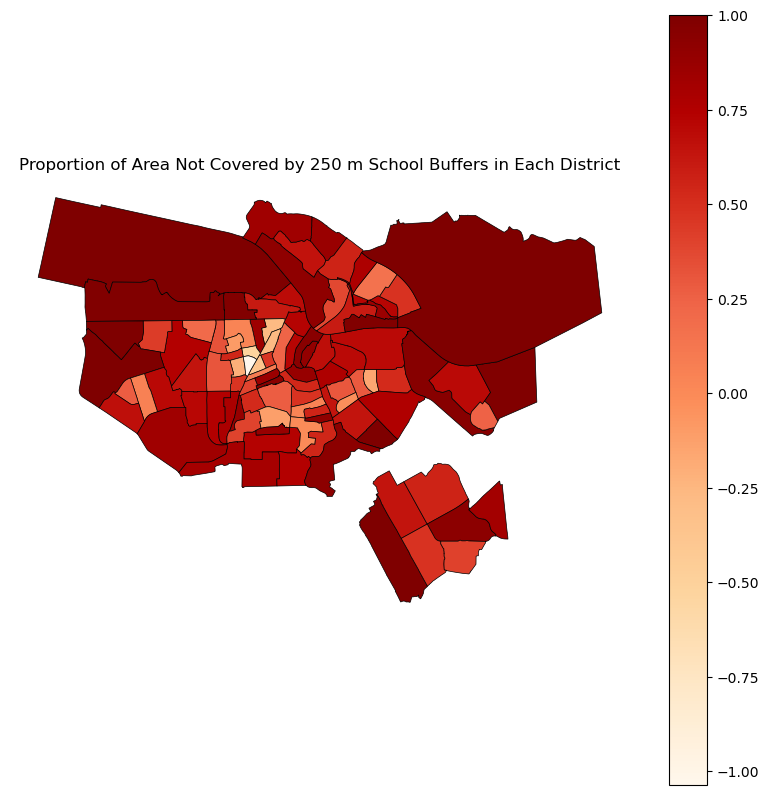

In [44]:
fig, ax = plt.subplots(1, 1, figsize = (10, 10))
districts.plot(
    ax = ax,
    column = "proport_not_covered",
    legend = True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("Proportion of Area Not Covered by 250 m School Buffers in Each District")
ax.axis("off")
plt.show()

In [16]:
buffers_gdf["dissolve_key"] = 1
buffers_gdf_dis = buffers_gdf.dissolve(by="dissolve_key")
buffers_gdf_dis.explore()


In [199]:
intersection_gdf = gpd.overlay(districts, buffers_gdf_dis, how="intersection")
intersection_gdf

,Buurtcombinatie,area_covered,total_area,area_not_covered,proport_not_covered,geometry
0,Burgwallen-Oude Zijde,4.039839e+04,4.047169e+05,3.643185e+05,0.900181,"POLYGON ((121909.092 487476.034, 121885.976 48..."
1,Burgwallen-Nieuwe Zijde,3.824516e+04,7.283908e+05,6.901457e+05,0.947494,"POLYGON ((121223.802 487705.216, 121232.96 487..."
2,Grachtengordel-West,1.605365e+05,5.690387e+05,4.085022e+05,0.717881,"MULTIPOLYGON (((121135.667 488099.599, 121155...."
3,Grachtengordel-Zuid,7.813743e+04,6.418352e+05,5.636977e+05,0.878259,"MULTIPOLYGON (((121546.952 486081.616, 121534...."
4,Nieuwmarkt/Lastage,3.516702e+05,1.066759e+06,7.150891e+05,0.670338,"POLYGON ((121811.548 487259.716, 121798.648 48..."
...,...,...,...,...,...,...
91,"Bijlmer Oost (E,G,K)",1.783331e+06,4.075905e+06,2.292573e+06,0.562470,"MULTIPOLYGON (((125828.65 481559.397, 125654.5..."
92,Nellestein,1.884215e+05,2.948612e+06,2.760191e+06,0.936098,"POLYGON ((127140.429 480357.835, 127245.862 48..."
93,Holendrecht/Reigersbos,1.411142e+06,2.712447e+06,1.301305e+06,0.479753,"MULTIPOLYGON (((127316.663 479068.389, 127323...."
94,Gein,1.137304e+06,1.921408e+06,7.841043e+05,0.408088,"MULTIPOLYGON (((127361.439 478780.184, 127361...."


In [20]:
intersection_gdf["area_covered"] = intersection_gdf.area

area_covered_by_district = (
    intersection_gdf.groupby("Buurtcombinatie")["area_covered"].sum().reset_index()
)
districts = districts.merge(area_covered_by_district, on="Buurtcombinatie", how="left")
# districts["area_covered"] = districts["area_covered"].fillna(0)

In [21]:
districts["area_covered"] = districts["area_covered"].fillna(0)

In [22]:
print(intersection_gdf.head())

           Buurtcombinatie                                           geometry  \
0    Burgwallen-Oude Zijde  POLYGON ((121909.092 487476.034, 121885.976 48...   
1  Burgwallen-Nieuwe Zijde  POLYGON ((121223.802 487705.216, 121232.96 487...   
2      Grachtengordel-West  POLYGON ((120633.864 486881.898, 120634.817 48...   
3      Grachtengordel-West  POLYGON ((121135.667 488099.599, 121155.065 48...   
4      Grachtengordel-Zuid  POLYGON ((121663.158 486111.876, 121668.251 48...   

    area_covered  
0   40398.394038  
1   38245.159992  
2   36235.438310  
3  124301.081123  
4   15081.269089  


In [23]:
districts["total_area"] = districts.area
districts["area_not_covered"] = districts["total_area"] - districts["area_covered"]
districts["proport_not_covered"] = districts["area_not_covered"] / districts["total_area"]

print(districts[["Buurtcombinatie", "total_area", "area_covered", "area_not_covered"]])

            Buurtcombinatie    total_area  area_covered  area_not_covered
0     Burgwallen-Oude Zijde  4.047169e+05  4.039839e+04      3.643185e+05
1   Burgwallen-Nieuwe Zijde  7.283908e+05  3.824516e+04      6.901457e+05
2       Grachtengordel-West  5.690387e+05  1.605365e+05      4.085022e+05
3       Grachtengordel-Zuid  6.418352e+05  7.813743e+04      5.636977e+05
4        Nieuwmarkt/Lastage  1.066759e+06  3.516702e+05      7.150891e+05
..                      ...           ...           ...               ...
94     Bijlmer Oost (E,G,K)  4.075905e+06  1.783331e+06      2.292573e+06
95               Nellestein  2.948612e+06  1.884215e+05      2.760191e+06
96   Holendrecht/Reigersbos  2.712447e+06  1.411142e+06      1.301305e+06
97                     Gein  1.921408e+06  1.137304e+06      7.841043e+05
98                 Driemond  2.023220e+06  3.575286e+05      1.665692e+06

[99 rows x 4 columns]


In [42]:
m_km = 10000000
total_area = districts["total_area"].sum() / m_km
total_covered_area = districts["area_covered"].sum() / m_km
total_not_covered_area = districts["area_not_covered"].sum() / m_km

print("\nSummary for All Districts:")
print(f"Total area: {total_area:.2f} km²")
print(f"Covered area: {total_covered_area:.2f} km²")
print(f"Not covered area: {total_not_covered_area:.2f} km²")


Summary for All Districts:
Total area: 21.95 km²
Covered area: 4.55 km²
Not covered area: 17.40 km²


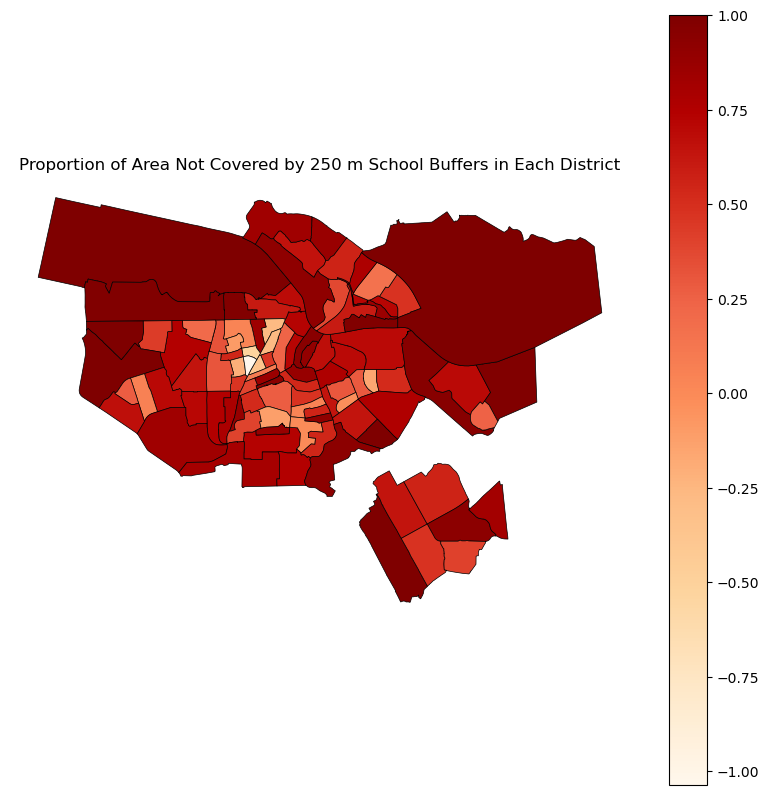

In [43]:
fig, ax = plt.subplots(1, 1, figsize = (10, 10))
districts.plot(
    ax = ax,
    column = "proport_not_covered",
    legend = True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("Proportion of Area Not Covered by 250 m School Buffers in Each District")
ax.axis("off")
plt.show()

In [31]:
url = "https://maps.amsterdam.nl/open_geodata/geojson_lnglat.php?KAARTLAAG=SPORT_OPENBAAR&THEMA=sport"

In [32]:
sports_gdf = gpd.read_file(url)

In [33]:
buffer_distance = 200
sports_buffers = sports_gdf.to_crs(epsg=28992).buffer(buffer_distance)
sports_buffers_gdf = gpd.GeoDataFrame(geometry=sports_buffers).set_crs(epsg=28992)

In [34]:
sports_buffers_gdf.explore()

In [35]:
sports_buffers_gdf["dissolve_key"] = 1
sports_buffers_dis = sports_buffers_gdf.dissolve(by="dissolve_key")

In [36]:
sports_buffers_dis.explore()

In [37]:
intersection_sports = gpd.overlay(districts, sports_buffers_dis, how = 'intersection')
intersection_sports.explore()

In [38]:
intersection_sports["area_covered"] = intersection_sports.area
area_covered_by_district = (
    intersection_sports.groupby("Buurtcombinatie")["area_covered"].sum().reset_index()
)

In [40]:
intersection_sports

,Buurtcombinatie,area_covered_x,total_area,area_not_covered,proport_not_covered,area_covered_y,area_covered,geometry
0,Burgwallen-Oude Zijde,4.039839e+04,4.047169e+05,3.643185e+05,0.900181,4.039839e+04,1.138553e+05,"MULTIPOLYGON (((121571.071 486846.754, 121561...."
1,Burgwallen-Nieuwe Zijde,3.824516e+04,7.283908e+05,6.901457e+05,0.947494,3.824516e+04,2.265690e+04,"MULTIPOLYGON (((121441.058 488019.514, 121499...."
2,Grachtengordel-West,1.605365e+05,5.690387e+05,4.085022e+05,0.717881,1.605365e+05,1.042614e+05,"MULTIPOLYGON (((120886.494 487918.613, 120950...."
3,Grachtengordel-Zuid,7.813743e+04,6.418352e+05,5.636977e+05,0.878259,7.813743e+04,9.581650e+04,"MULTIPOLYGON (((121395.787 486710.862, 121400...."
4,Nieuwmarkt/Lastage,3.516702e+05,1.066759e+06,7.150891e+05,0.670338,3.516702e+05,2.816732e+05,"MULTIPOLYGON (((122748.335 487295.676, 122746...."
...,...,...,...,...,...,...,...,...
92,"Bijlmer Centrum (D,F,H)",1.131581e+06,3.158006e+06,2.026425e+06,0.641679,1.131581e+06,1.162022e+06,"MULTIPOLYGON (((126476.02 480387.179, 126466.3..."
93,"Bijlmer Oost (E,G,K)",1.783331e+06,4.075905e+06,2.292573e+06,0.562470,1.783331e+06,2.062966e+06,"MULTIPOLYGON (((128097.774 481759.824, 128155...."
94,Nellestein,1.884215e+05,2.948612e+06,2.760191e+06,0.936098,1.884215e+05,4.626403e+05,"MULTIPOLYGON (((127440.665 480523.592, 127440...."
95,Holendrecht/Reigersbos,1.411142e+06,2.712447e+06,1.301305e+06,0.479753,1.411142e+06,1.608093e+06,"MULTIPOLYGON (((127462.523 478127.605, 127457...."
